# Köppen–Geiger via ERA5 na MESMA janela do artigo original (1950–1990)

Quarta variante da análise, pensada especificamente para isolar uma variável: **mesma
fonte de dado (ERA5), mesmo algoritmo, mesma bbox/máscara do Brasil — só muda o
período**, de 1996–2025 (`notebook_brasil.ipynb`) para **1950–1990** (41 anos), a
janela textual do artigo (*"adequate temporal data series (> 25 years between 1950
and 1990)"*, Alvares et al. 2013).

**Por que isso importa:** nos dois notebooks anteriores (ERA5 1996–2025 e estações
BDMEP ~2000–2025) encontramos a mesma divergência em relação ao artigo — zona B
(árido/semiárido) maior, zona C (subtropical) menor — em duas fontes de dado
independentes. Isso levanta duas hipóteses não excludentes:

1. **Viés sistemático de fonte de dado** (reanálise/krigagem moderna tende a superestimar
   área árida em relação ao método do artigo), ou
2. **Mudança climática real** entre a linha de base 1950–1990 e o período atual.

Rodar o ERA5 na janela 1950–1990 ajuda a separar essas hipóteses: se o resultado bater
com o artigo aqui, a hipótese (2) ganha força — a diferença nos notebooks anteriores
seria sobre *quando*, não *como* os dados foram coletados. Se ainda divergir do artigo
nesta mesma janela temporal, a hipótese (1) (viés do ERA5/reanálise) ganha força.

**O algoritmo de classificação de Köppen (`koppen_classify`) é o mesmo dos outros três
notebooks, copiado sem nenhuma alteração.**

**Ressalva de qualidade já conhecida**: a densidade de observações assimiladas pelo
ERA5 nas décadas de 1950-60 no Brasil era bem mais esparsa que hoje (poucos satélites,
poucas radiossondas) — a confiabilidade do reanálise tende a cair quanto mais se volta
no tempo dentro dessa janela.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import earthkit.data as ekd
import geopandas as gpd
from shapely import contains_xy

GRIB_PATH = "73887683a4e22dc3b5a188fffc098169.grib"
np.set_printoptions(suppress=True)


In [2]:
# Contorno dos estados e do país (IBGE) -- mesmos arquivos/função dos notebooks anteriores
BR_STATES = gpd.read_file("data/brazil_states.geojson")
BR_STATES["geometry"] = BR_STATES.geometry.simplify(0.03, preserve_topology=True)


def add_state_borders(ax, color="#404040", lw=0.6, alpha=0.75):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    BR_STATES.boundary.plot(ax=ax, color=color, linewidth=lw, alpha=alpha, zorder=5)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


BR_COUNTRY = gpd.read_file("data/brasil_ibge.geojson")
BR_COUNTRY_GEOM = BR_COUNTRY.union_all()


## 1. Carregar o GRIB (1950–1990) e corrigir alinhamento temporal

Mesma particularidade de metadados do `notebook_brasil.ipynb`: `tp` é codificado com o
tempo referenciado ao início da previsão (18h do dia anterior + passo de 12h), `2t` usa
o tempo de validade direto. Verificamos a correspondência mês-a-mês antes de realinhar
pela coordenada limpa do `2t` (não altera nenhum valor, só a coordenada de tempo).

In [3]:
source = ekd.from_source("file", GRIB_PATH)
fieldlist = source.to_fieldlist()

idx_2t = [i for i in range(len(fieldlist)) if fieldlist[i].metadata("shortName") == "2t"]
idx_tp = [i for i in range(len(fieldlist)) if fieldlist[i].metadata("shortName") == "tp"]
print(f"Campos 2t: {len(idx_2t)}   Campos tp: {len(idx_tp)}  (esperado: 41 anos × 12 meses = 492 cada)")

ds_2t = fieldlist[idx_2t].to_xarray().rename({"forecast_reference_time": "time"})
ds_tp = fieldlist[idx_tp].to_xarray().rename({"forecast_reference_time": "time"})

tempo_2t = pd.DatetimeIndex(ds_2t["time"].values).to_period("M")
tempo_tp = (pd.DatetimeIndex(ds_tp["time"].values) + pd.Timedelta(hours=12)).to_period("M")
assert len(tempo_2t) == len(tempo_tp), "2t e tp tem numero de passos de tempo diferente"
assert (tempo_2t == tempo_tp).all(), "2t e tp nao correspondem mes-a-mes na mesma ordem"
print("Correspondência mês-a-mês entre 2t e tp verificada: OK")
print(f"Período coberto: {tempo_2t.min()} a {tempo_2t.max()}")

ds_tp = ds_tp.assign_coords(time=ds_2t["time"].values)
ds = xr.merge([ds_2t, ds_tp])

# Unidades -- identico aos notebooks anteriores
ds["t2m_c"] = ds["2t"] - 273.15
days_in_month = ds["time"].dt.days_in_month
ds["precip_mm"] = ds["tp"] * days_in_month * 1000.0

ds["t2m_c"].attrs["units"] = "degC"
ds["precip_mm"].attrs["units"] = "mm/month"

ds


Campos 2t: 492   Campos tp: 492  (esperado: 41 anos × 12 meses = 492 cada)


Correspondência mês-a-mês entre 2t e tp verificada: OK
Período coberto: 1950-01 a 1990-12


<xarray.Dataset> Size: 408MB
Dimensions:    (time: 492, latitude: 161, longitude: 161)
Coordinates:
  * time       (time) datetime64[us] 4kB 1950-01-01 1950-02-01 ... 1990-12-01
  * latitude   (latitude) float64 1kB 6.0 5.75 5.5 5.25 ... -33.5 -33.75 -34.0
  * longitude  (longitude) float64 1kB -74.0 -73.75 -73.5 ... -34.5 -34.25 -34.0
Data variables:
    2t         (time, latitude, longitude) float64 102MB 291.5 288.1 ... 291.5
    tp         (time, latitude, longitude) float64 102MB ...
    t2m_c      (time, latitude, longitude) float64 102MB 18.39 14.93 ... 18.39
    precip_mm  (time, latitude, longitude) float64 102MB 166.4 155.5 ... 164.4
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## 2. Recorte geográfico do Brasil (malha oficial do IBGE)

Mesma bbox e mesma máscara (ponto-em-polígono) do `notebook_brasil.ipynb`.

Grade total: 25921 células (161 lat × 161 lon, 0.25°)
Células dentro do Brasil (IBGE): 11346 (43.8% da bbox)
Área aproximada coberta pela máscara: 8,530,545 km²  (área oficial: 8.510.000 km²)


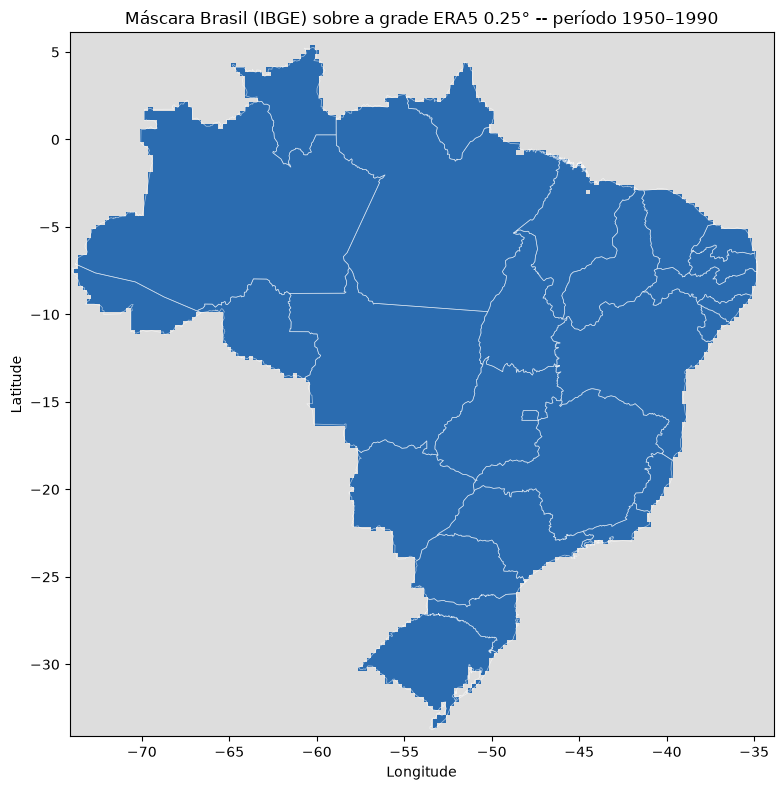

In [4]:
lats = ds["latitude"].values
lons = ds["longitude"].values
LON2D, LAT2D = np.meshgrid(lons, lats)

brasil_mask = contains_xy(BR_COUNTRY_GEOM, LON2D, LAT2D)
print(f"Grade total: {brasil_mask.size} células ({len(lats)} lat × {len(lons)} lon, 0.25°)")
print(f"Células dentro do Brasil (IBGE): {brasil_mask.sum()} ({100*brasil_mask.sum()/brasil_mask.size:.1f}% da bbox)")

R = 6371.0
dlat_km = 0.25 * (np.pi / 180) * R
area_por_lat = dlat_km * (0.25 * (np.pi / 180) * R * np.cos(np.radians(lats)))
area_total = (brasil_mask * area_por_lat[:, None]).sum()
print(f"Área aproximada coberta pela máscara: {area_total:,.0f} km²  (área oficial: 8.510.000 km²)")

fig, ax = plt.subplots(figsize=(8, 8))
ax.pcolormesh(lons, lats, brasil_mask, cmap=ListedColormap(["#dddddd", "#2b6cb0"]), shading="auto")
add_state_borders(ax, color="white", lw=0.5, alpha=0.6)
ax.set_title("Máscara Brasil (IBGE) sobre a grade ERA5 0.25° -- período 1950–1990")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 3. Análise exploratória (1950–1990)

Mesmo tratamento de `min_count=1` do `notebook_brasil.ipynb` para a soma anual de
precipitação (evita que células fora do Brasil, todas `NaN`, contribuam com zeros
espúrios na média espacial).

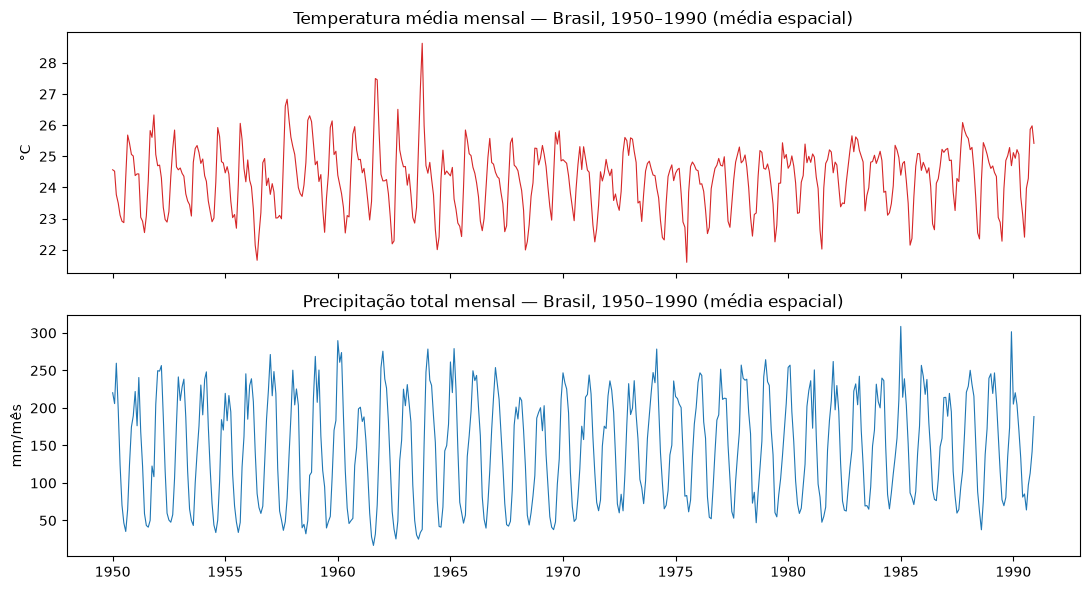

In [5]:
brasil_da = xr.DataArray(brasil_mask, dims=["latitude", "longitude"],
                          coords={"latitude": ds.latitude, "longitude": ds.longitude})

t2m_masked = ds["t2m_c"].where(brasil_da)
precip_masked = ds["precip_mm"].where(brasil_da)

regional_t = t2m_masked.mean(dim=["latitude", "longitude"])
regional_p = precip_masked.mean(dim=["latitude", "longitude"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
regional_t.plot(ax=axes[0], color="tab:red", lw=0.8)
axes[0].set_title("Temperatura média mensal — Brasil, 1950–1990 (média espacial)")
axes[0].set_ylabel("°C")
axes[0].set_xlabel("")

regional_p.plot(ax=axes[1], color="tab:blue", lw=0.8)
axes[1].set_title("Precipitação total mensal — Brasil, 1950–1990 (média espacial)")
axes[1].set_ylabel("mm/mês")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()


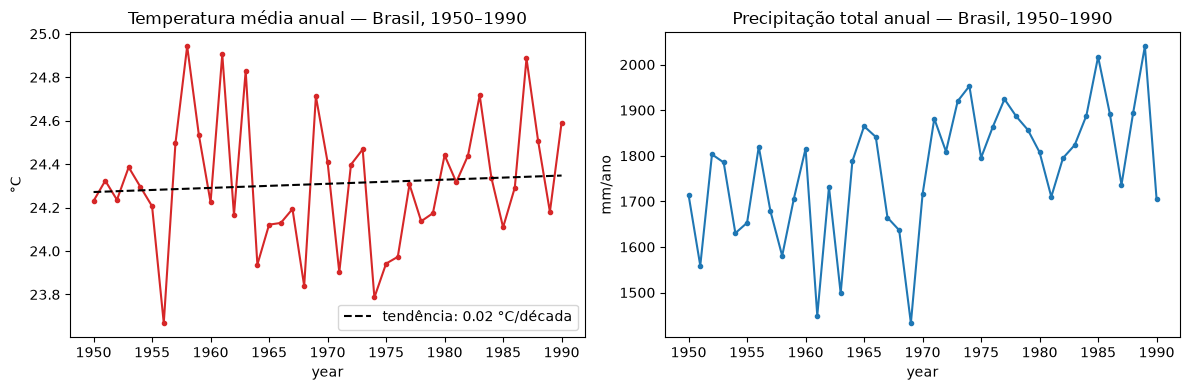

In [6]:
annual_t = t2m_masked.groupby("time.year").mean(dim=["time", "latitude", "longitude"])
annual_p_percell = precip_masked.groupby("time.year").sum(dim="time", min_count=1)
annual_p = annual_p_percell.mean(dim=["latitude", "longitude"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual_t.plot(ax=axes[0], marker="o", ms=3, color="tab:red")
z = np.polyfit(annual_t["year"], annual_t.values, 1)
axes[0].plot(annual_t["year"], np.polyval(z, annual_t["year"]), "k--",
             label=f"tendência: {z[0]*10:.2f} °C/década")
axes[0].set_title("Temperatura média anual — Brasil, 1950–1990")
axes[0].set_ylabel("°C")
axes[0].legend()

annual_p.plot(ax=axes[1], marker="o", ms=3, color="tab:blue")
axes[1].set_title("Precipitação total anual — Brasil, 1950–1990")
axes[1].set_ylabel("mm/ano")

plt.tight_layout()
plt.show()


## 4. Climatologia mensal (1950–1990)

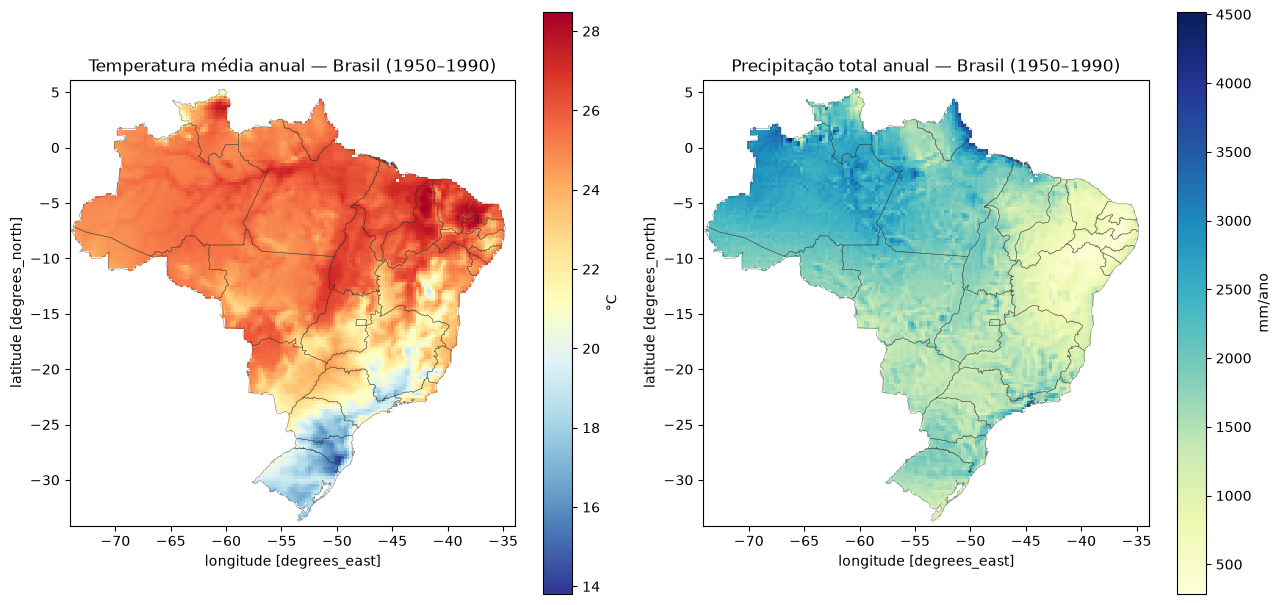

In [7]:
t_clim = t2m_masked.groupby("time.month").mean(dim="time").sortby("month")
p_clim = precip_masked.groupby("time.month").mean(dim="time").sortby("month")

mat_map = t_clim.mean(dim="month")
map_map = p_clim.sum(dim="month", min_count=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 10))
mat_map.plot(ax=axes[0], cmap="RdYlBu_r", cbar_kwargs={"label": "°C", "shrink": 0.6})
axes[0].set_title("Temperatura média anual — Brasil (1950–1990)")
add_state_borders(axes[0], color="#333333", lw=0.4, alpha=0.6)
axes[0].set_aspect("equal")

map_map.plot(ax=axes[1], cmap="YlGnBu", cbar_kwargs={"label": "mm/ano", "shrink": 0.6})
axes[1].set_title("Precipitação total anual — Brasil (1950–1990)")
add_state_borders(axes[1], color="#333333", lw=0.4, alpha=0.6)
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()


## 5. Algoritmo de classificação de Köppen–Geiger

**Função copiada, caractere por caractere, do notebook original** — sem nenhuma
alteração, idêntica aos outros três notebooks. Os mesmos 15 testes sintéticos são
reexecutados logo abaixo.

In [8]:
def koppen_classify(T, P, summer_idx=(9, 10, 11, 0, 1, 2), winter_idx=(3, 4, 5, 6, 7, 8)):
    """
    T, P: arrays (12, lat, lon) com climatologia mensal de temperatura (°C) e
          precipitacao (mm/mes), mes 0 = Janeiro ... mes 11 = Dezembro.
    summer_idx / winter_idx: indices de mes (0-based) do semestre de verao e inverno
          para o hemisferio da regiao (default: hemisferio sul).
    Retorna: array 2D de strings com o codigo Koppen (ex: 'Aw', 'Cfa', 'BSh', ...).
             Celulas sem dado valido (oceano/mascara) recebem 'NA'.
    """
    T = np.asarray(T)
    P = np.asarray(P)

    # celulas com qualquer mes faltante (ex: oceano dentro da bbox) ficam de fora
    valid = ~(np.isnan(T).any(axis=0) | np.isnan(P).any(axis=0))

    MAT = T.mean(axis=0)
    MAP = P.sum(axis=0)
    Tcold = T.min(axis=0)
    Thot = T.max(axis=0)
    Pdry = P.min(axis=0)
    TM10 = (T > 10).sum(axis=0)

    Psum = P[list(summer_idx)]
    Pwin = P[list(winter_idx)]
    Psdry, Pswet = Psum.min(axis=0), Psum.max(axis=0)
    Pwdry, Pwwet = Pwin.min(axis=0), Pwin.max(axis=0)

    frac_win = Pwin.sum(axis=0) / MAP
    frac_sum = Psum.sum(axis=0) / MAP
    Pthresh = np.where(frac_win >= 0.7, 2 * MAT,
                        np.where(frac_sum >= 0.7, 2 * MAT + 28, 2 * MAT + 14))

    code = np.full(MAT.shape, "NA", dtype="<U3")
    unresolved = valid.copy()

    # --- B: clima arido (checado primeiro, tem prioridade sobre A/C/D) ---
    is_B = unresolved & (MAP < 10 * Pthresh)
    is_h = MAT >= 18
    is_arid = is_B & (MAP < 5 * Pthresh)
    is_semiarid = is_B & ~is_arid
    code[is_arid & is_h] = "BWh"
    code[is_arid & ~is_h] = "BWk"
    code[is_semiarid & is_h] = "BSh"
    code[is_semiarid & ~is_h] = "BSk"
    unresolved &= ~is_B

    # --- A: clima tropical ---
    is_A = unresolved & (Tcold >= 18)
    is_Af = is_A & (Pdry >= 60)
    is_Am = is_A & ~is_Af & (Pdry >= (100 - MAP / 25))
    is_Aws = is_A & ~is_Af & ~is_Am
    dry_month = np.argmin(P, axis=0)
    dry_in_summer = np.isin(dry_month, list(summer_idx))
    is_As = is_Aws & dry_in_summer
    is_Aw = is_Aws & ~dry_in_summer
    code[is_Af] = "Af"
    code[is_Am] = "Am"
    code[is_As] = "As"
    code[is_Aw] = "Aw"
    unresolved &= ~is_A

    # --- E: clima polar ---
    is_E = unresolved & (Thot < 10)
    code[is_E & (Thot >= 0)] = "ET"
    code[is_E & (Thot < 0)] = "EF"
    unresolved &= ~is_E

    # --- C / D: temperado / continental ---
    is_CD = unresolved
    is_D = is_CD & (Tcold < -3)
    is_C = is_CD & ~is_D

    is_f = is_CD & (Pdry > 40)
    is_w = is_CD & ~is_f & (Pswet >= 10 * Pwdry)
    is_s = is_CD & ~is_f & ~is_w & (Pwwet >= 3 * Psdry)
    # fallback: quando nao se enquadra perfeitamente em w/s mas Pdry<=40, classifica como f
    # (evita celulas sem classificacao por empates nas condicoes de fronteira)
    is_unclassified_rain = is_CD & ~is_f & ~is_w & ~is_s
    is_f = is_f | is_unclassified_rain

    is_a = is_CD & (Thot >= 22)
    is_b = is_CD & (Thot < 22) & (TM10 >= 4)
    is_c = is_CD & (Thot < 22) & (TM10 < 4) & (Tcold >= -38)
    is_d = is_CD & (Tcold < -38)

    for zone_mask, zone_letter in [(is_C, "C"), (is_D, "D")]:
        for rain_mask, rain_letter in [(is_f, "f"), (is_w, "w"), (is_s, "s")]:
            m = zone_mask & rain_mask
            code[m & is_a] = zone_letter + rain_letter + "a"
            code[m & is_b] = zone_letter + rain_letter + "b"
            code[m & is_c] = zone_letter + rain_letter + "c"
            if zone_letter == "D":
                code[m & is_d] = zone_letter + rain_letter + "d"

    assert (code[~valid] == "NA").all()
    assert (code[valid] != "NA").all(), "existem celulas com dado valido que nao foram classificadas"
    return code, valid


In [9]:
def _classify_profile(T12, P12):
    """Classifica um unico perfil mensal (listas de 12 valores)."""
    T = np.array(T12, dtype=float).reshape(12, 1, 1)
    P = np.array(P12, dtype=float).reshape(12, 1, 1)
    return koppen_classify(T, P)[0][0, 0]


# Perfis sinteticos (hemisferio sul: verao = out-mar, inverno = abr-set).
# Jan .......................................................... Dez
CASOS_TESTE = {
    "Af":  ([27] * 12,
            [280, 280, 300, 300, 300, 160, 120, 80, 100, 140, 180, 220]),
    "Am":  ([27] * 12,
            [300, 350, 400, 400, 380, 250, 130, 40, 15, 30, 80, 150]),
    "Aw":  ([26] * 12,
            [280, 260, 270, 150, 40, 2, 1, 5, 40, 180, 230, 250]),
    "As":  ([26] * 12,          # seca no verao (set-dez), chuva no inverno
            [60, 90, 150, 200, 250, 280, 220, 110, 30, 20, 25, 40]),
    "BSh": ([26] * 12,
            [80, 110, 130, 60, 20, 5, 2, 1, 2, 10, 30, 60]),
    "BWh": ([28] * 12,
            [5, 5, 3, 2, 1, 0, 0, 0, 1, 2, 3, 5]),
    "Cfa": ([24, 24, 22, 19, 16, 13, 13, 14, 16, 19, 21, 23],
            [120, 130, 130, 140, 120, 140, 130, 140, 140, 120, 110, 120]),
    "Cfb": ([20.5, 20, 19, 17, 14, 13, 13, 14, 15, 17, 18, 20],
            [170, 150, 130, 90, 100, 110, 100, 80, 120, 140, 120, 150]),
    "Cwa": ([23.5, 23.5, 23, 21, 19, 17.5, 17.5, 19, 21, 22, 23, 23],
            [280, 200, 160, 60, 40, 20, 15, 20, 50, 130, 180, 260]),
    "Cwb": ([21.5, 21.5, 21, 20, 18, 16.5, 15.5, 17, 19, 20, 21, 21],
            [300, 180, 150, 60, 25, 12, 10, 12, 35, 120, 220, 300]),
    "Cwc": ([11.5, 11, 9.5, 8, 6, 4.5, 4.5, 6, 8, 9.5, 10, 11],   # so 3 meses > 10 C
            [200, 160, 150, 60, 40, 20, 15, 25, 60, 140, 180, 210]),
    "Csa": ([22.7, 22.5, 22, 21, 19, 18, 17.5, 17.9, 19, 20.5, 22, 22.7],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "Csb": ([21.5, 21.3, 21, 20, 19, 17.5, 17, 17.5, 18.5, 19.5, 20.5, 21.5],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "ET":  ([5, 5, 4, 2, 0, -2, -3, -1, 1, 3, 4, 5], [50] * 12),
    "EF":  ([-5] * 12, [30] * 12),
}

falhas = []
for esperado, (T12, P12) in CASOS_TESTE.items():
    obtido = _classify_profile(T12, P12)
    if obtido != esperado:
        falhas.append((esperado, obtido))
    print(f"{'OK   ' if obtido == esperado else 'FALHA'} esperado={esperado:<4} obtido={obtido:<4}"
          f"  Tcold={min(T12):5.1f}  Thot={max(T12):5.1f}  MAP={sum(P12):5.0f}mm  Pdry={min(P12):3.0f}mm")

assert not falhas, f"casos que falharam: {falhas}"
print(f"\n{len(CASOS_TESTE)}/{len(CASOS_TESTE)} casos corretos -- algoritmo idêntico aos outros notebooks")


OK    esperado=Af   obtido=Af    Tcold= 27.0  Thot= 27.0  MAP= 2460mm  Pdry= 80mm
OK    esperado=Am   obtido=Am    Tcold= 27.0  Thot= 27.0  MAP= 2525mm  Pdry= 15mm
OK    esperado=Aw   obtido=Aw    Tcold= 26.0  Thot= 26.0  MAP= 1708mm  Pdry=  1mm
OK    esperado=As   obtido=As    Tcold= 26.0  Thot= 26.0  MAP= 1475mm  Pdry= 20mm
OK    esperado=BSh  obtido=BSh   Tcold= 26.0  Thot= 26.0  MAP=  510mm  Pdry=  1mm
OK    esperado=BWh  obtido=BWh   Tcold= 28.0  Thot= 28.0  MAP=   27mm  Pdry=  0mm
OK    esperado=Cfa  obtido=Cfa   Tcold= 13.0  Thot= 24.0  MAP= 1540mm  Pdry=110mm
OK    esperado=Cfb  obtido=Cfb   Tcold= 13.0  Thot= 20.5  MAP= 1460mm  Pdry= 80mm
OK    esperado=Cwa  obtido=Cwa   Tcold= 17.5  Thot= 23.5  MAP= 1415mm  Pdry= 15mm
OK    esperado=Cwb  obtido=Cwb   Tcold= 15.5  Thot= 21.5  MAP= 1424mm  Pdry= 10mm
OK    esperado=Cwc  obtido=Cwc   Tcold=  4.5  Thot= 11.5  MAP= 1260mm  Pdry= 15mm
OK    esperado=Csa  obtido=Csa   Tcold= 17.5  Thot= 22.7  MAP=  810mm  Pdry= 20mm
OK    esperado=C

## 6. Classificação e mapa final (1950–1990)

In [10]:
T_arr = t_clim.transpose("month", "latitude", "longitude").values
P_arr = p_clim.transpose("month", "latitude", "longitude").values
koppen_codes, valid_mask = koppen_classify(T_arr, P_arr)
territorio_mask = valid_mask & brasil_mask

print(f"Células com dado válido: {valid_mask.sum()}")
print(f"Células dentro do Brasil (IBGE): {brasil_mask.sum()}")
print(f"Interseção (classificadas): {territorio_mask.sum()}")

unique, counts = np.unique(koppen_codes[territorio_mask], return_counts=True)
tabela_koppen = pd.DataFrame({"climate": unique, "n_pixels": counts,
                               "%": 100 * counts / counts.sum()}).sort_values("%", ascending=False)
tabela_koppen


Células com dado válido: 11346
Células dentro do Brasil (IBGE): 11346
Interseção (classificadas): 11346


,climate,n_pixels,%
3,Aw,4829,42.561255
0,Af,2151,18.958223
1,Am,1982,17.468711
6,Cfa,794,6.998061
4,BSh,670,5.905165
2,As,369,3.252247
7,Cfb,305,2.688172
8,Cwa,149,1.313238
9,Cwb,80,0.705094
5,BWh,17,0.149833


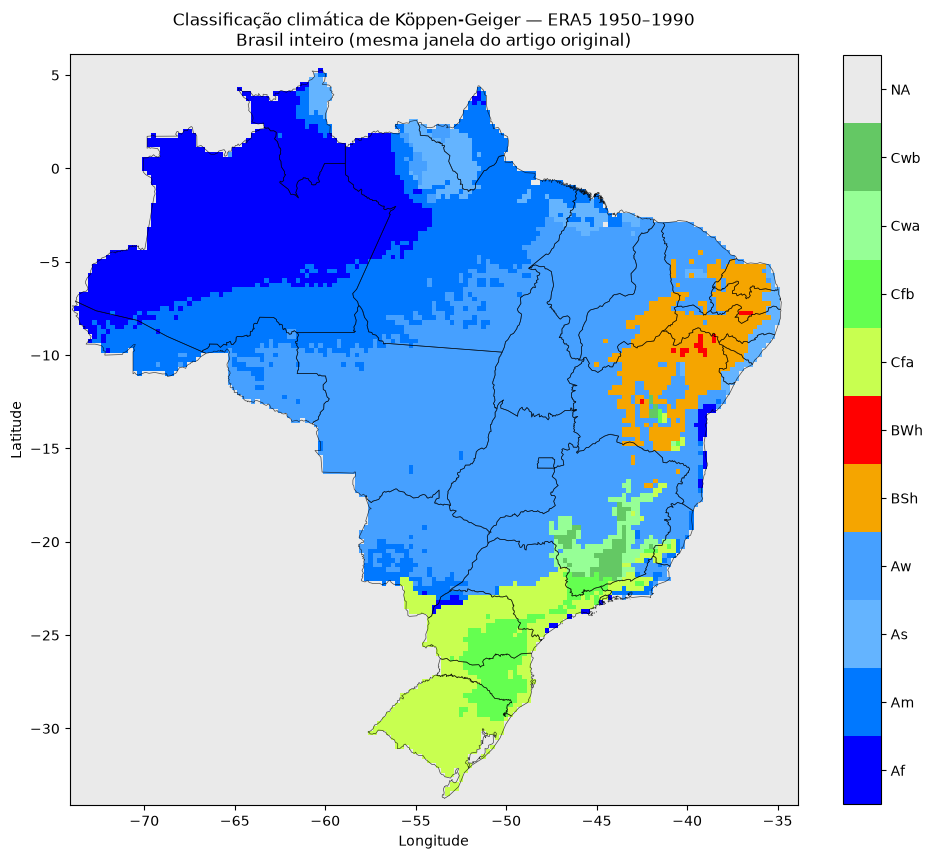

In [11]:
KOPPEN_COLORS = {
    "Af": "#0000FF", "Am": "#0078FF", "Aw": "#46A0FF", "As": "#64B4FF",
    "BWh": "#FF0000", "BWk": "#FFA0A0", "BSh": "#F5A500", "BSk": "#FFDC64",
    "Csa": "#FFFF00", "Csb": "#C8C800", "Csc": "#969600",
    "Cwa": "#96FF96", "Cwb": "#64C864", "Cwc": "#329632",
    "Cfa": "#C8FF50", "Cfb": "#64FF50", "Cfc": "#32C800",
    "Dsa": "#FF00FF", "Dsb": "#C800C8", "Dsc": "#963296", "Dsd": "#966496",
    "Dwa": "#ABB1FF", "Dwb": "#5A77DB", "Dwc": "#4C51B5", "Dwd": "#320087",
    "Dfa": "#00FFFF", "Dfb": "#37C8FF", "Dfc": "#007D7D", "Dfd": "#00465F",
    "ET": "#B3B3B3", "EF": "#696969",
    "NA": "#EAEAEA",
}

codes_brasil = np.where(territorio_mask, koppen_codes, "NA")
codes_present = sorted(np.unique(codes_brasil))
cmap = ListedColormap([KOPPEN_COLORS.get(c, "#FF00FF") for c in codes_present])
code_to_int = {c: i for i, c in enumerate(codes_present)}
int_grid = np.vectorize(code_to_int.get)(codes_brasil)

fig, ax = plt.subplots(figsize=(10, 11))
im = ax.pcolormesh(lons, lats, int_grid, cmap=cmap,
                    vmin=-0.5, vmax=len(codes_present) - 0.5, shading="auto")
ax.set_title("Classificação climática de Köppen-Geiger — ERA5 1950–1990\nBrasil inteiro (mesma janela do artigo original)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
add_state_borders(ax, color="black", lw=0.5, alpha=0.7)

cbar = fig.colorbar(im, ax=ax, ticks=range(len(codes_present)), shrink=0.7)
cbar.ax.set_yticklabels(codes_present)

plt.tight_layout()
plt.show()


## 7. Comparação de quatro pontas: artigo × ERA5 1950–1990 × ERA5 1996–2025 × estações

Este é o teste que motivou todo o notebook: **isolar a variável período** mantendo a
fonte de dado (ERA5) e o algoritmo fixos. Se a linha "ERA5 1950–1990" ficar perto do
artigo, a hipótese de mudança climática real entre as duas linhas de base ganha força;
se ainda divergir do artigo do mesmo jeito que o ERA5 1996–2025, a hipótese de viés
sistemático do ERA5/reanálise ganha força.

In [12]:
zonas_validas = np.array([c[0] for c in codes_brasil[territorio_mask]])
unique_z, counts_z = np.unique(zonas_validas, return_counts=True)
tabela_zonas = pd.DataFrame({"zona": unique_z, "% ERA5 1950-1990 (este notebook)": 100 * counts_z / counts_z.sum()})
tabela_zonas = tabela_zonas.set_index("zona")

artigo = pd.Series({"A": 81.4, "B": 4.9, "C": 13.7}, name="% artigo (Alvares et al. 2013, 1950-1990)")
era5_recente = pd.Series({"A": 82.3, "B": 8.2, "C": 9.5}, name="% ERA5 1996-2025 (notebook_brasil.ipynb)")
estacoes = pd.Series({"A": 82.4, "B": 7.9, "C": 9.7}, name="% estações ~2000-2025 (notebook_estacoes.ipynb)")

comparacao = (tabela_zonas
              .join(artigo, how="outer")
              .join(era5_recente, how="outer")
              .join(estacoes, how="outer")
              .fillna(0).round(1))
comparacao = comparacao[["% artigo (Alvares et al. 2013, 1950-1990)",
                          "% ERA5 1950-1990 (este notebook)",
                          "% ERA5 1996-2025 (notebook_brasil.ipynb)",
                          "% estações ~2000-2025 (notebook_estacoes.ipynb)"]]
comparacao


,"% artigo (Alvares et al. 2013, 1950-1990)",% ERA5 1950-1990 (este notebook),% ERA5 1996-2025 (notebook_brasil.ipynb),% estações ~2000-2025 (notebook_estacoes.ipynb)
zona,,,,
A,81.4,82.2,82.3,82.4
B,4.9,6.1,8.2,7.9
C,13.7,11.7,9.5,9.7


## 9. Correção de viés do ERA5 com estações convencionais do INMET (mesmo período)

A Seção 7 mostrou que o ERA5 1950–1990 ainda diverge do artigo principalmente na
fronteira Am/Aw (26,8 dos 36,9 pontos percentuais de divergência total), um padrão
consistente com viés seco de precipitação do ERA5. Agora corrigimos isso usando
**estações convencionais reais do INMET, do mesmo período** (646 arquivos BDMEP, rede
convencional — código numérico de 5 dígitos, não a rede automática usada no
`notebook_estacoes.ipynb`), para isolar a variável "fonte" sem reintroduzir a confusão
de período que motivou este notebook inteiro.

**Método**: para cada mês-calendário, calculamos o erro `ERA5 − estação` no ponto de
cada estação, espacializamos esse erro por krigagem ordinária (mesma técnica usada nos
resíduos de temperatura do `notebook_estacoes.ipynb`), e subtraímos a superfície de
erro interpolada da grade bruta do ERA5 — um "regression-kriging" aplicado como
correção de viés, não para preencher uma grade vazia (o ERA5 já é completo), mas para
puxar o campo de volta na direção da observação real.

Arquivos de estação convencional encontrados: 646


Descartadas (sem coluna de precip/temp): 119
Descartadas (< 5 anos em algum mês): 122
Estações convencionais utilizáveis: 405
Dentro da bbox do ERA5: 405


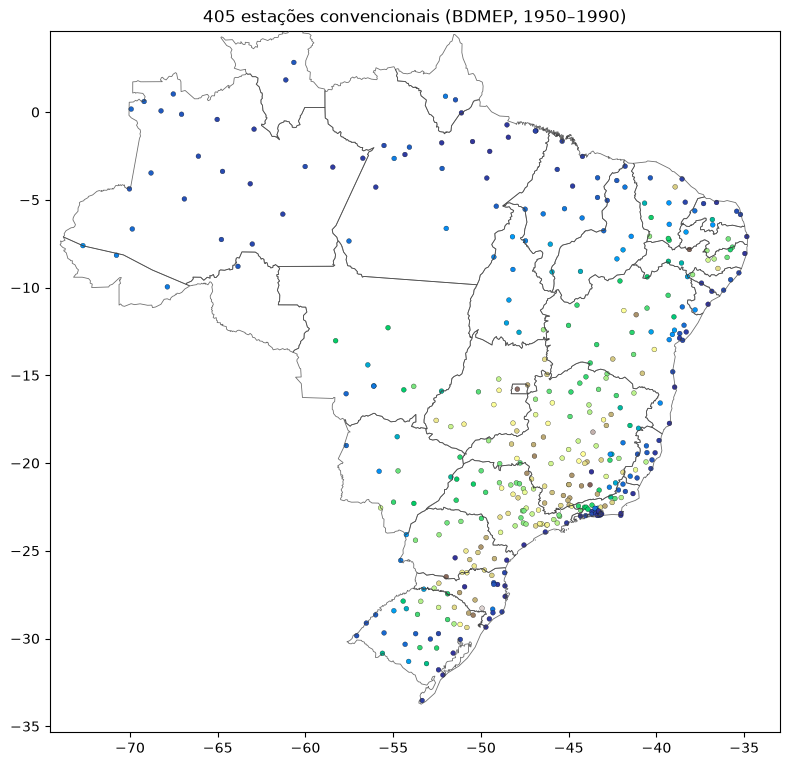

In [13]:
import glob
import os
from pykrige.ok import OrdinaryKriging

CONV_DIR = "data/bdmep_convencional_1950_1990"
MIN_ANOS_POR_MES = 5


def parse_estacao_conv(path):
    with open(path, encoding="utf-8") as f:
        linhas = f.readlines()
    meta = {}
    for linha in linhas[:9]:
        if ":" in linha:
            k, v = linha.split(":", 1)
            meta[k.strip()] = v.strip()
    idx_cabecalho = next(i for i, l in enumerate(linhas) if l.startswith("Data Medicao"))
    df = pd.read_csv(path, sep=";", skiprows=idx_cabecalho, encoding="utf-8", decimal=",",
                      na_values=["null", ""])
    df = df.dropna(axis=1, how="all")
    df.columns = [c.strip() for c in df.columns]
    return meta, df


arquivos_conv = sorted(glob.glob(os.path.join(CONV_DIR, "dados_*.csv")))
print(f"Arquivos de estação convencional encontrados: {len(arquivos_conv)}")

linhas_conv = []
descartadas_sem_coluna = 0
descartadas_pouco_dado = 0

for path in arquivos_conv:
    meta, df = parse_estacao_conv(path)
    col_p = [c for c in df.columns if "PRECIPITACAO" in c]
    col_t = [c for c in df.columns if "TEMPERATURA" in c]
    if not col_p or not col_t:
        descartadas_sem_coluna += 1
        continue

    df["Data Medicao"] = pd.to_datetime(df["Data Medicao"])
    df["mes"] = df["Data Medicao"].dt.month
    df = df.rename(columns={col_p[0]: "precip", col_t[0]: "temp"})

    clim = df.groupby("mes")[["precip", "temp"]].agg(["mean", "count"])
    if clim[("precip", "count")].min() < MIN_ANOS_POR_MES or clim[("temp", "count")].min() < MIN_ANOS_POR_MES:
        descartadas_pouco_dado += 1
        continue

    linhas_conv.append({
        "codigo": meta["Codigo Estacao"], "nome": meta["Nome"],
        "lat": float(meta["Latitude"]), "lon": float(meta["Longitude"]), "alt": float(meta["Altitude"]),
        **{f"precip_{m}": clim.loc[m, ("precip", "mean")] for m in range(1, 13)},
        **{f"temp_{m}": clim.loc[m, ("temp", "mean")] for m in range(1, 13)},
    })

estacoes_conv = pd.DataFrame(linhas_conv)
print(f"Descartadas (sem coluna de precip/temp): {descartadas_sem_coluna}")
print(f"Descartadas (< {MIN_ANOS_POR_MES} anos em algum mês): {descartadas_pouco_dado}")
print(f"Estações convencionais utilizáveis: {len(estacoes_conv)}")

# so estacoes dentro da bbox do ERA5 1950-1990 (lat 6/-34, lon -74/-34)
dentro_bbox = (estacoes_conv["lat"].between(lats.min(), lats.max()) &
               estacoes_conv["lon"].between(lons.min(), lons.max()))
print(f"Dentro da bbox do ERA5: {dentro_bbox.sum()}")
estacoes_conv = estacoes_conv[dentro_bbox].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(estacoes_conv["lon"], estacoes_conv["lat"], c=estacoes_conv["alt"], cmap="terrain",
           s=12, edgecolor="black", linewidth=0.2, vmin=0, vmax=1500)
add_state_borders(ax)
ax.set_aspect("equal")
ax.set_title(f"{len(estacoes_conv)} estações convencionais (BDMEP, 1950–1990)")
plt.tight_layout()
plt.show()


## 10. Krigagem do erro e grade corrigida

Para cada mês: amostra o ERA5 bruto no pixel mais próximo de cada estação, calcula o
erro, krige esse erro (modelo esférico, graus geográficos — mesma escolha do artigo e
dos notebooks anteriores) sobre toda a grade do Brasil, e subtrai da grade bruta.

In [14]:
# pontos-alvo: so dentro do Brasil (territorio_mask ja calculado na Secao 6)
lat_pts = LAT2D[territorio_mask]
lon_pts = LON2D[territorio_mask]


def pixel_valido_mais_proximo(lat, lon, janela=5):
    """Indice (i,j) do pixel valido (territorio_mask True) mais proximo de (lat,lon).
    Estacoes litoraneas podem cair no pixel ERA5 mais proximo por coordenada bruta
    mas esse pixel estar fora do territorio_mask (oceano/fora do Brasil na grade
    0.25 graus) -- nesse caso busca o vizinho valido mais proximo numa janela."""
    i0 = int(np.abs(lats - lat).argmin())
    j0 = int(np.abs(lons - lon).argmin())
    if territorio_mask[i0, j0]:
        return i0, j0
    melhor, melhor_dist = None, np.inf
    for di in range(-janela, janela + 1):
        for dj in range(-janela, janela + 1):
            i, j = i0 + di, j0 + dj
            if 0 <= i < len(lats) and 0 <= j < len(lons) and territorio_mask[i, j]:
                dist = di ** 2 + dj ** 2
                if dist < melhor_dist:
                    melhor, melhor_dist = (i, j), dist
    if melhor is None:
        raise ValueError(f"nenhum pixel valido a {janela} celulas de ({lat}, {lon})")
    return melhor


# indice do pixel ERA5 mais proximo (e valido) de cada estacao
idx_est = [pixel_valido_mais_proximo(la, lo) for la, lo in zip(estacoes_conv["lat"], estacoes_conv["lon"])]
i_est = np.array([i for i, j in idx_est])
j_est = np.array([j for i, j in idx_est])
n_deslocadas = sum(1 for (i, j), la, lo in zip(idx_est, estacoes_conv["lat"], estacoes_conv["lon"])
                    if (i, j) != (int(np.abs(lats - la).argmin()), int(np.abs(lons - lo).argmin())))
print(f"Estações cujo pixel bruto caía fora do território e foram realocadas: {n_deslocadas}")

T_corrigido = np.full_like(T_arr, np.nan)
P_corrigido = np.full_like(P_arr, np.nan)

diagnosticos_corr = []
for m in range(12):  # m=0..11 (Jan..Dez), T_arr/P_arr ja estao nessa ordem
    mes_num = m + 1
    era5_t_na_estacao = T_arr[m, i_est, j_est]
    era5_p_na_estacao = P_arr[m, i_est, j_est]

    erro_t = era5_t_na_estacao - estacoes_conv[f"temp_{mes_num}"].values
    erro_p_log = np.log1p(era5_p_na_estacao) - np.log1p(estacoes_conv[f"precip_{mes_num}"].values)

    ok_t = OrdinaryKriging(estacoes_conv["lon"].values, estacoes_conv["lat"].values, erro_t,
                            variogram_model="spherical", coordinates_type="geographic")
    erro_t_grid, _ = ok_t.execute("points", lon_pts, lat_pts)

    ok_p = OrdinaryKriging(estacoes_conv["lon"].values, estacoes_conv["lat"].values, erro_p_log,
                            variogram_model="spherical", coordinates_type="geographic")
    erro_p_log_grid, _ = ok_p.execute("points", lon_pts, lat_pts)

    T_mes_bruto_pts = T_arr[m][territorio_mask]
    P_mes_bruto_pts = P_arr[m][territorio_mask]

    T_mes_corrigido_pts = T_mes_bruto_pts - erro_t_grid
    P_mes_corrigido_pts = np.clip(np.expm1(np.log1p(P_mes_bruto_pts) - erro_p_log_grid), 0, None)

    T_corrigido[m][territorio_mask] = T_mes_corrigido_pts
    P_corrigido[m][territorio_mask] = P_mes_corrigido_pts

    diagnosticos_corr.append({
        "mes": mes_num,
        "erro_T_medio_C": round(erro_t.mean(), 2),
        "erro_T_dp_C": round(erro_t.std(), 2),
        "erro_P_log_medio": round(erro_p_log.mean(), 3),
        "correcao_T_media_na_grade_C": round(erro_t_grid.mean(), 2),
    })

diag_corr_df = pd.DataFrame(diagnosticos_corr)
diag_corr_df


Estações cujo pixel bruto caía fora do território e foram realocadas: 22


,mes,erro_T_medio_C,erro_T_dp_C,erro_P_log_medio,correcao_T_media_na_grade_C
0,1,-0.03,0.88,0.007,-0.00
1,2,-0.11,0.86,0.006,-0.08
2,3,-0.15,0.87,0.024,-0.12
3,4,-0.09,0.88,0.031,-0.09
4,5,0.11,0.91,-0.015,0.10
5,6,0.32,0.98,-0.058,0.40
6,7,0.37,1.06,-0.112,0.51
7,8,0.39,1.11,-0.093,0.63
8,9,0.45,1.09,-0.066,0.46
9,10,0.28,1.00,-0.033,0.46


## 11. Reclassificação com dados corrigidos e comparação final

Mesmo `koppen_classify`, sem alteração — só trocamos `T_arr`/`P_arr` brutos pelos
corrigidos.

In [15]:
koppen_codes_corr, valid_mask_corr = koppen_classify(T_corrigido, P_corrigido)
territorio_mask_corr = valid_mask_corr & brasil_mask

unique_c, counts_c = np.unique(koppen_codes_corr[territorio_mask_corr], return_counts=True)
tabela_corr = pd.DataFrame({"climate": unique_c, "n_pixels": counts_c,
                             "%": 100 * counts_c / counts_c.sum()}).sort_values("%", ascending=False)

# Tabela 3 do artigo (Alvares et al. 2013), linha 'Brasil'
artigo_tipo = {
    "Af": 22.6, "Am": 27.5, "Aw": 25.8, "As": 5.5,
    "BSh": 4.9,
    "Cfa": 6.5, "Cfb": 2.6, "Cwa": 2.5, "Cwb": 2.1,
}

bruto_tipo = dict(zip(tabela_koppen["climate"], tabela_koppen["%"]))
corr_tipo = dict(zip(tabela_corr["climate"], tabela_corr["%"]))

tipos = sorted(set(artigo_tipo) | set(bruto_tipo) | set(corr_tipo))
linhas_comp = []
for t in tipos:
    a = artigo_tipo.get(t, 0.0)
    b = bruto_tipo.get(t, 0.0)
    c = corr_tipo.get(t, 0.0)
    linhas_comp.append({
        "tipo": t, "artigo_%": a,
        "ERA5_bruto_%": round(b, 1), "dif_bruto_pp": round(b - a, 1),
        "ERA5_corrigido_%": round(c, 1), "dif_corrigido_pp": round(c - a, 1),
    })

comp_tipo_df = pd.DataFrame(linhas_comp).sort_values("artigo_%", ascending=False)
print("Soma |diferença| bruto:     ", round(comp_tipo_df["dif_bruto_pp"].abs().sum(), 1), "pp")
print("Soma |diferença| corrigido: ", round(comp_tipo_df["dif_corrigido_pp"].abs().sum(), 1), "pp")
comp_tipo_df


Soma |diferença| bruto:      36.9 pp
Soma |diferença| corrigido:  36.0 pp


,tipo,artigo_%,ERA5_bruto_%,dif_bruto_pp,ERA5_corrigido_%,dif_corrigido_pp
1,Am,27.5,17.5,-10.0,18.5,-9.0
3,Aw,25.8,42.6,16.8,43.2,17.4
0,Af,22.6,19.0,-3.6,19.0,-3.6
6,Cfa,6.5,7.0,0.5,7.1,0.6
2,As,5.5,3.3,-2.2,3.6,-1.9
4,BSh,4.9,5.9,1.0,3.3,-1.6
7,Cfb,2.6,2.7,0.1,2.4,-0.2
8,Cwa,2.5,1.3,-1.2,2.2,-0.3
9,Cwb,2.1,0.7,-1.4,0.7,-1.4
5,BWh,0.0,0.1,0.1,0.0,0.0


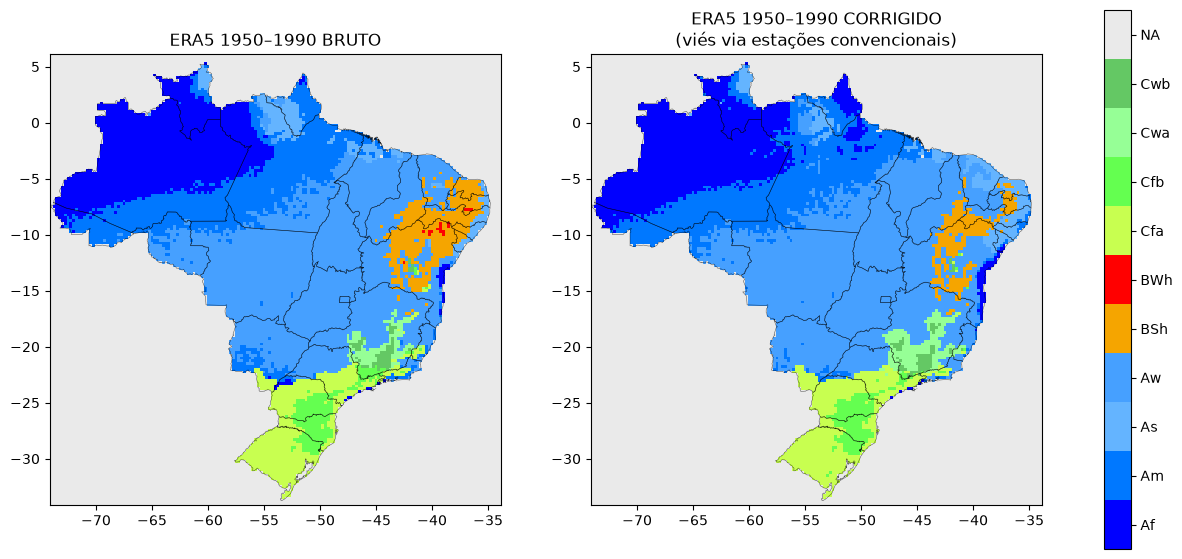

In [16]:
codes_brasil_corr = np.where(territorio_mask_corr, koppen_codes_corr, "NA")

codes_present_ambos = sorted(set(np.unique(codes_brasil)) | set(np.unique(codes_brasil_corr)))
cmap_ambos = ListedColormap([KOPPEN_COLORS.get(c, "#FF00FF") for c in codes_present_ambos])
code_to_int_ambos = {c: i for i, c in enumerate(codes_present_ambos)}

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, codes, titulo in [(axes[0], codes_brasil, "ERA5 1950–1990 BRUTO"),
                           (axes[1], codes_brasil_corr, "ERA5 1950–1990 CORRIGIDO\n(viés via estações convencionais)")]:
    int_grid_ab = np.vectorize(code_to_int_ambos.get)(codes)
    im = ax.pcolormesh(lons, lats, int_grid_ab, cmap=cmap_ambos,
                        vmin=-0.5, vmax=len(codes_present_ambos) - 0.5, shading="auto")
    ax.set_title(titulo)
    add_state_borders(ax, color="black", lw=0.4, alpha=0.6)
    ax.set_aspect("equal")

cbar = fig.colorbar(im, ax=axes, ticks=range(len(codes_present_ambos)), shrink=0.7)
cbar.ax.set_yticklabels(codes_present_ambos)
plt.show()


## 13. Por que a correção não resolveu Am/Aw: densidade de estação na faixa de transição

A correção de viés (Seções 9-11) mal tocou na troca Am↔Aw. Hipótese: a rede
convencional tem um vazio de cobertura bem em cima da faixa de transição
Amazônia-Cerrado — justamente onde a fronteira Am/Aw mais importa. Testamos isso
calculando, para cada célula classificada, a distância até a estação convencional mais
próxima.

Distância média/mediana à estação convencional mais próxima, por tipo climático:
         mean  median  count
codigo                      
Cfb      34.8    33.8    305
Cwb      38.0    34.4     80
Cwa      39.2    38.7    149
Cfa      45.2    41.0    794
BSh      58.2    53.8    670
BWh      67.6    69.9     17
As      114.5    90.6    369
Aw      115.3    85.0   4829
Af      131.7   119.6   2151
Am      136.8   124.7   1982

Am vs Aw especificamente:
  Am: média=136.8km  mediana=124.7km  n=1982
  Aw: média=115.3km  mediana=85.0km  n=4829

Proporção Aw cresce conforme a célula fica mais longe de qualquer estação:
  > 100km (4817 células, 42.5% do território): Aw=41.7%  Am=25.2%  Af=27.3%
  > 150km (2826 células, 24.9% do território): Aw=42.8%  Am=27.8%  Af=25.9%
  > 200km (1605 células, 14.1% do território): Aw=50.2%  Am=25.9%  Af=20.7%
  > 250km (941 células, 8.3% do território): Aw=59.5%  Am=18.6%  Af=18.4%

Faixa de transição Amazônia-Cerrado (lat -6/-14°, lon -58/-48°):
  distância

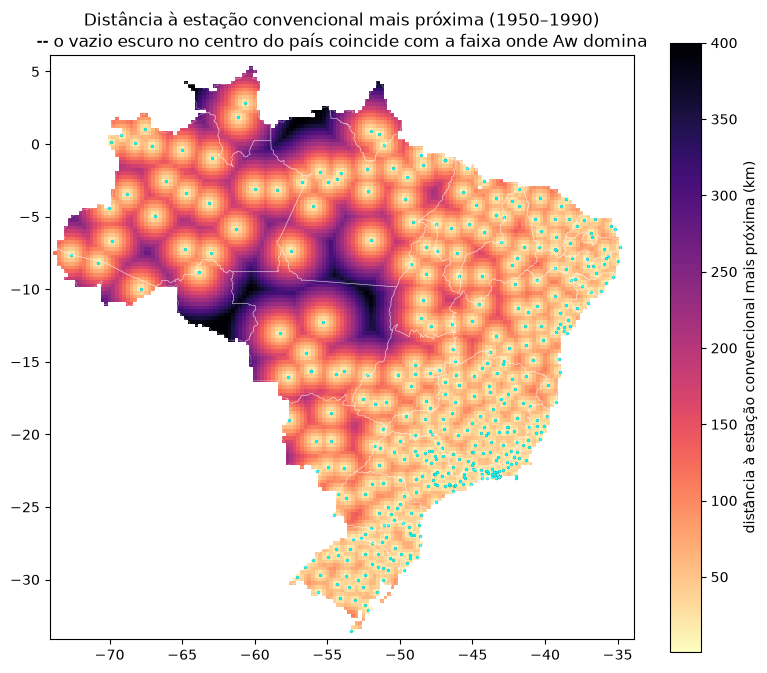

In [17]:
R_TERRA = 111.0  # km por grau, aproximacao suficiente para esta analise

dist_km = np.full(len(lat_pts), np.inf)
for _, est in estacoes_conv.iterrows():
    d = np.sqrt(((lat_pts - est.lat) * R_TERRA) ** 2 +
                ((lon_pts - est.lon) * R_TERRA * np.cos(np.radians(lat_pts))) ** 2)
    dist_km = np.minimum(dist_km, d)

df_dist = pd.DataFrame({"lat": lat_pts, "lon": lon_pts,
                         "codigo": koppen_codes[territorio_mask], "dist_km": dist_km})

print("Distância média/mediana à estação convencional mais próxima, por tipo climático:")
print(df_dist.groupby("codigo")["dist_km"].agg(["mean", "median", "count"]).sort_values("mean").round(1))

print("\nAm vs Aw especificamente:")
for cod in ["Am", "Aw"]:
    sub = df_dist[df_dist.codigo == cod]["dist_km"]
    print(f"  {cod}: média={sub.mean():.1f}km  mediana={sub.median():.1f}km  n={len(sub)}")

print("\nProporção Aw cresce conforme a célula fica mais longe de qualquer estação:")
for limiar in [100, 150, 200, 250]:
    deserto = df_dist.dist_km > limiar
    comp = df_dist[deserto].codigo.value_counts(normalize=True) * 100
    print(f"  > {limiar}km ({deserto.sum()} células, {100*deserto.sum()/len(df_dist):.1f}% do território): "
          f"Aw={comp.get('Aw',0):.1f}%  Am={comp.get('Am',0):.1f}%  Af={comp.get('Af',0):.1f}%")

# faixa de transicao Amazonia-Cerrado: norte do MT, sul do PA/TO
zona_transicao = (df_dist.lat < -6) & (df_dist.lat > -14) & (df_dist.lon > -58) & (df_dist.lon < -48)
print(f"\nFaixa de transição Amazônia-Cerrado (lat -6/-14°, lon -58/-48°):")
print(f"  distância média à estação: {df_dist[zona_transicao].dist_km.mean():.0f} km "
      f"(Brasil todo: {df_dist.dist_km.mean():.0f} km)")
comp_zona = (df_dist[zona_transicao].codigo.value_counts(normalize=True) * 100).round(1)
print(f"  composição: {dict(comp_zona)}")

fig, ax = plt.subplots(figsize=(8, 9))
dist_grid = np.full(LAT2D.shape, np.nan)
dist_grid[territorio_mask] = dist_km
im = ax.pcolormesh(lons, lats, dist_grid, cmap="magma_r", shading="auto", vmax=400)
fig.colorbar(im, ax=ax, label="distância à estação convencional mais próxima (km)", shrink=0.7)
ax.scatter(estacoes_conv.lon, estacoes_conv.lat, s=5, c="cyan", edgecolor="black", linewidth=0.1)
add_state_borders(ax, color="white", lw=0.4, alpha=0.5)
ax.set_title("Distância à estação convencional mais próxima (1950–1990)\n"
              "-- o vazio escuro no centro do país coincide com a faixa onde Aw domina")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 14. Teste (negativo): correção por taxa de lapso para Cwa/Cwb

A divergência que sobra em Cwa/Cwb depois da correção por estação (Seção 11) foi
atribuída, nas ressalvas dos notebooks anteriores, à suavização de relevo do ERA5 em
baixa resolução. A estratégia óbvia para atacar isso é uma **correção por taxa de
lapso** (lapse-rate correction): comparar a altitude real (ETOPO) com a altitude
"implícita" de cada pixel do ERA5, e aplicar uma correção de temperatura proporcional à
diferença — a mesma técnica usada por produtos como WorldClim/CHELSA para downscaling
de reanálise.

Testamos isso diretamente nos dados de estação antes de implementar, e o resultado é
negativo: **o efeito de altitude estatisticamente mais forte que encontramos não é
aplicável a uma correção em nível de grade.**

In [18]:
from sklearn.linear_model import LinearRegression

dem = xr.open_dataset("data/etopo2022_60s_brasil.nc")
dem = dem.assign_coords(longitude=(((dem.longitude + 180) % 360) - 180)).sortby("longitude")

# altitude "implicita" de cada pixel ERA5 onde uma estacao foi amostrada (ETOPO no centro do pixel)
alt_pixel_era5 = dem["z"].sel(
    latitude=xr.DataArray(lats[i_est], dims="p"),
    longitude=xr.DataArray(lons[j_est], dims="p"),
    method="nearest",
).values
alt_pixel_era5 = np.clip(alt_pixel_era5, 0, None)

alt_estacao = estacoes_conv["alt"].values
alt_diff = alt_estacao - alt_pixel_era5  # quanto a estacao esta acima/abaixo da media do pixel

print(f"Altitude real da estação:        média={alt_estacao.mean():6.0f}m  dp={alt_estacao.std():6.0f}m")
print(f"Altitude do pixel ERA5 (ETOPO):  média={alt_pixel_era5.mean():6.0f}m  dp={alt_pixel_era5.std():6.0f}m")
print(f"Diferença (ponto - pixel):       média={alt_diff.mean():6.0f}m  dp={alt_diff.std():6.0f}m\n")

linhas_teste = []
preditores = {
    "alt_estacao (ponto, NÃO aplicável à grade)": alt_estacao,
    "alt_pixel_ERA5 (aplicável à grade)": alt_pixel_era5,
    "alt_diff ponto-pixel (NÃO aplicável à grade)": alt_diff,
}
for m in range(12):
    mes_num = m + 1
    era5_t = T_arr[m, i_est, j_est]
    era5_p = P_arr[m, i_est, j_est]
    erro_t = era5_t - estacoes_conv[f"temp_{mes_num}"].values
    erro_p_log = np.log1p(era5_p) - np.log1p(estacoes_conv[f"precip_{mes_num}"].values)

    for nome_pred, X in preditores.items():
        reg_t = LinearRegression().fit(X.reshape(-1, 1), erro_t)
        reg_p = LinearRegression().fit(X.reshape(-1, 1), erro_p_log)
        linhas_teste.append({
            "mes": mes_num, "preditor": nome_pred,
            "slope_T_C_por_100m": round(reg_t.coef_[0] * 100, 3),
            "R2_T": round(reg_t.score(X.reshape(-1, 1), erro_t), 3),
            "R2_P_log": round(reg_p.score(X.reshape(-1, 1), erro_p_log), 3),
        })

teste_df = pd.DataFrame(linhas_teste)
resumo_teste = teste_df.groupby("preditor")[["slope_T_C_por_100m", "R2_T", "R2_P_log"]].mean().round(3)
resumo_teste.columns = ["slope T médio (°C/100m)", "R² médio T", "R² médio P (log)"]
resumo_teste


Altitude real da estação:        média=   401m  dp=   334m
Altitude do pixel ERA5 (ETOPO):  média=   426m  dp=   342m
Diferença (ponto - pixel):       média=   -25m  dp=   168m



,slope T médio (°C/100m),R² médio T,R² médio P (log)
preditor,,,
alt_diff ponto-pixel (NÃO aplicável à grade),0.205,0.132,0.009
"alt_estacao (ponto, NÃO aplicável à grade)",0.076,0.074,0.015
alt_pixel_ERA5 (aplicável à grade),0.023,0.010,0.023


**Conclusão:** o preditor com sinal mais forte (altitude real da estação, R²≈0,07-0,10,
slope positivo e fisicamente coerente) só existe *no ponto da estação* — ele mede o
descompasso entre um ponto específico (às vezes no topo de um morro) e a média de área
de ~28×28 km que o pixel ERA5 representa. Isso é ruído de amostragem ponto-vs-área, não
um viés sistemático: toda célula da grade de saída *já é* uma média de área, não existe
"ponto" dentro dela para corrigir.

O único preditor que seria de fato aplicável a uma correção em nível de grade —
altitude média do próprio pixel ERA5 (ETOPO) — tem R² médio de apenas ~0,02, ou seja,
explica ~2% da variância do erro. Não é um sinal exploitável.

Para precipitação o resultado é ainda mais claro: R² ≈ 0,01-0,03 em todos os
preditores, essencialmente zero (esperado — chuva orográfica depende de orientação da
vertente em relação ao vento, não só de altitude, uma relação não-linear que uma
regressão linear simples não capta).

**Não implementamos essa correção.** A divergência residual em Cwa/Cwb (depois da
correção por estação da Seção 11) provavelmente vem de outra fonte — viés geral de
temperatura não correlacionado com altitude, ou sensibilidade de limiar parecida com o
caso Am/Aw, só que numa escala espacial menor. Isso fica como questão em aberto.

## 15. Ressalvas metodológicas

O algoritmo passa nos mesmos 15/15 testes sintéticos dos outros três notebooks — as
ressalvas abaixo são sobre os **dados de entrada**, não sobre a classificação em si.

- **Confiabilidade do ERA5 cai quanto mais se volta no tempo**: a densidade de
  observações assimiladas (radiossondas, estações de superfície, e principalmente
  satélites, que só começam a contribuir de forma relevante a partir de fins dos anos
  1970) era muito menor nas décadas de 1950–60 do que hoje. O ERA5 é internamente
  consistente (mesmo modelo, mesma física ao longo de todo o período), mas a
  *acurácia* da reanálise para os primeiros ~20 anos desta janela é inferior à dos
  últimos ~20 anos.
- **Mesma bbox, grades diferentes**: o request de 1950–1990 usou uma bbox ligeiramente
  diferente do request de 1996–2025 (ambos a 0,25°, mas `[6,-74,-34,-34]` vs.
  `[5.25,-73,-33,-34]` aproximadamente) — por isso não foi feito um mapa de diferença
  célula-a-célula entre os dois períodos nesta rodada; a comparação é só agregada
  (Seção 7).
- **O artigo usa estações reais interpoladas por krigagem + regressão por altitude**;
  mesmo rodando o ERA5 na mesma janela temporal, a diferença de *método* continua
  sendo uma variável não isolada pelo teste da Seção 7 — só a variável "período" foi
  isolada ali.
- **A correção de viés (Seções 9-11) praticamente não resolveu a troca Am↔Aw**
  (36,9 → 36,0 pp de diferença total; Aw até piorou ligeiramente, +16,8 → +17,4 pp) —
  **e a Seção 13 explica por quê**: a rede convencional tem um vazio de cobertura de
  até ~400 km de raio bem em cima da faixa de transição Amazônia-Cerrado (norte do
  MT/sul do PA-TO), que é exatamente onde a fronteira Am/Aw mais importa. Nessa faixa
  específica, a distância média à estação mais próxima (186 km) é 69% maior que a
  média nacional (110 km), e a composição climática ali é 82% Aw / 18% Am — e a
  proporção de Aw cresce de forma monotônica conforme a célula fica mais isolada de
  estações (41,7% entre as células a >100km de qualquer estação, chegando a 59,5%
  entre as células a >250km). A krigagem do erro nessa região é essencialmente
  extrapolação de longo alcance, sem sinal local real para corrigir.
- **A correção foi treinada e aplicada nos mesmos pontos de estação** (sem separação
  treino/teste) — a redução marginal na diferença percentual é, portanto, uma medida
  otimista do que a correção consegue fazer nos próprios pontos onde foi calibrada, não
  uma validação fora da amostra.
- **Correção por taxa de lapso (altitude) testada e descartada (Seção 14)**: o sinal de
  altitude mais forte que encontramos (R²≈0,07-0,10) existe só no ponto da estação —
  reflete descompasso ponto-vs-área, não um viés de grade corrigível. O único sinal
  transferível para a grade (altitude média do pixel ERA5) tem R²≈0,02, inútil na
  prática. A divergência residual em Cwa/Cwb fica sem explicação causal confirmada.